# 0. Mon setup colab

In [1]:
# OPTIONAL: run once in a fresh Colab runtime; skip during local development.
INSTALL_COLAB_PACKAGES = True  # Set to True to install; reset to False afterward.

import sys
import subprocess

# Detect Colab; otherwise use the local .venv.
try:
    from google.colab import output
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not IN_COLAB:
    print("Local environment: skipped. Use uv sync in your terminal.")
elif not INSTALL_COLAB_PACKAGES:
    print("Installation skipped. Set INSTALL_COLAB_PACKAGES = True if this is a fresh Colab runtime.")
else:
    # Install into the Python running these cells.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "uv>=0.8,<1"])
    packages = [
        "pandas>=2.2,<4",
        "requests>=2.31,<3",
        "plotly>=6,<7",
        "ipywidgets>=8.1,<9",
    ]
    subprocess.check_call([sys.executable, "-m", "uv", "pip", "install",
                           "--python", sys.executable, *packages])
    print("Installation finished. Restart the session if Colab requests it.")


Installation finished. Restart the session if Colab requests it.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!git clone https://github.com/ammou35/LNH-data-science.git

Cloning into 'LNH-data-science'...
remote: Enumerating objects: 380, done.
remote: Counting objects: 100% (69/69), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 380 (delta 50), reused 45 (delta 42), pack-reused 311 (from 1)
Receiving objects: 100% (380/380), 960.88 KiB | 9.42 MiB/s, done.
Resolving deltas: 100% (188/188), done.


In [2]:
%cd LNH-data-science/

/content/LNH-data-science


In [3]:
!git switch advanced_viz

Already on 'advanced_viz'
Your branch is up to date with 'origin/advanced_viz'.


In [4]:
!git pull

remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Total 5 (delta 4), reused 5 (delta 4), pack-reused 0 (from 0)
Unpacking objects: 100% (5/5), 9.84 KiB | 2.46 MiB/s, done.
From https://github.com/ammou35/LNH-data-science
   5a5331e..e065cfb  main       -> origin/main
Already up to date.


In [5]:
import os
os.environ['NHL_DATA_DIR'] = '/content/drive/MyDrive/ift6758/data/raw'

In [6]:
%cd data_science_project/

/content/LNH-data-science/data_science_project


In [7]:
!uv sync

Resolved 179 packages in 59ms
Checked 129 packages in 181ms


In [8]:
import os
from ift6758.data.tidy_data import *
from ift6758.data.nhl import GAME_TYPE_CODE, get_data_dir
from pathlib import Path
import pandas as pd
import json

In [9]:
data_dir = Path("/content/drive/MyDrive/ift6758/data/")
raw_data_dir = data_dir / "raw"
processed_data_dir = data_dir / "processed"

print(raw_data_dir)
print(processed_data_dir)

/content/drive/MyDrive/ift6758/data/raw
/content/drive/MyDrive/ift6758/data/processed


In [12]:
# On cree les dataframes pour chaque saison
dataframes = []

for season in range(2016, 2024):
  filepath = Path(processed_data_dir / f"shots_{season}.csv")
  if (filepath.is_file()):
    print(f"Le fichier de la saison {season} existe deja, on passe a la saison suivante")
    df = pd.read_csv(filepath)
  else:
    try:
      print(f"Creation du tidy df de la saison {season}...")
      df = season_to_pandas(season, data_dir=raw_data_dir)
    except:
      print("Erreur")

    print(f"Saison {season} faite")
    print(f"Sauvegarde de shots_{season}...")
    #save_to_csv(df, f"shots_{season}", processed_data_dir)

  dataframes.append(df)

# On regroupe tout dans un seul dataframe
combined_shots = pd.concat(dataframes, ignore_index=True)
print("C'est tout bon!")

Le fichier de la saison 2016 existe deja, on passe a la saison suivante
Le fichier de la saison 2017 existe deja, on passe a la saison suivante
Le fichier de la saison 2018 existe deja, on passe a la saison suivante
Le fichier de la saison 2019 existe deja, on passe a la saison suivante
Le fichier de la saison 2020 existe deja, on passe a la saison suivante
Le fichier de la saison 2021 existe deja, on passe a la saison suivante
Le fichier de la saison 2022 existe deja, on passe a la saison suivante
Le fichier de la saison 2023 existe deja, on passe a la saison suivante
C'est tout bon!


# 5. Visualisations avancées : cartes de tirs

## Consignes

Le dernier ensemble de visualisations que vous créerez sont des cartes de tirs pour une équipe donnée de la LNH, pour une année et une saison données. Un excellent exemple de ces graphiques, avec une description détaillée de comment les lire, se trouve sur le [site web de hockeyviz](https://hockeyviz.com/howto/shotMap) (qui est une excellente ressource pour beaucoup de choses en science des données appliquée au hockey). Notez que vous devrez créer ces figures à partir de zéro ; pour cette étape, vous ne pouvez utiliser aucune bibliothèque qui génère des figures spécifiques au domaine (hockey) pour vous. Vous recevrez un exemple d'image de patinoire ayant le bon ratio.

Pour créer ces figures, vous devez :

1. Vous assurer que vous pouvez travailler correctement avec les coordonnées des événements. Cela inclut de vous assurer que les tirs sont du bon côté de la patinoire (en raison des changements de période, ou parce que les équipes commencent de côtés différents pendant un match), ainsi que de pouvoir convertir les coordonnées physiques en coordonnées de pixels sur la figure.  
2. Calculer des statistiques agrégées des emplacements de tirs pour l'ensemble de la ligue afin d'obtenir le *taux de tirs moyen par heure de la ligue*. Pour chaque zone (*bin*) spatiale, divisez le nombre de tirs de toutes les équipes par `2 * nombre de matchs de la ligue` pour cette saison : chaque match contribue deux heures-équipe selon l'hypothèse de 60 minutes. Vous pouvez faire quelques hypothèses simplificatrices :  
   - Vous pouvez supposer que tous les tirs sont à forces égales ; cela signifie que vous pouvez simplement agréger tous les tirs plutôt que de déterminer si un tir a été effectué à forces égales ou non (rappel : Q 4.2).  
   - Vous pouvez supposer que chaque match dure 60 minutes.  
3. Regrouper les tirs par équipe et utiliser le *taux de tirs moyen par heure* de la ligue calculé ci-dessus pour calculer le *taux de tirs excédentaire par heure*. Pour chaque zone, divisez le nombre de tirs de l'équipe par son nombre de matchs dans cette saison, puis soustrayez le taux de la ligue pour cette zone. Rapportez la différence brute en **tirs par heure-équipe**.  
4. Faire des choix appropriés pour regrouper (*binning*) vos données lors de leur affichage. Vous pouvez également envisager d'utiliser des techniques de lissage pour rendre vos cartes de tirs plus lisibles. Une stratégie courante consiste à utiliser l'estimation par noyau (*kernel density estimation*) avec un noyau gaussien.  
5. Rendre le graphique interactif, avec des options pour sélectionner l'**équipe**. La façon la plus simple de le faire est d'utiliser un outil comme plotly ou bokeh. Une petite démo simple de ce que vous pouvez faire avec plotly se trouve [ici](https://plotly.com/python/dropdowns/).  
6. Produire **une figure interactive pour chaque saison de 2016-17 à 2020-21** (inclusivement). Vous devez **seulement créer les figures de la zone offensive** ; vous n'avez rien à faire pour la zone défensive. Comme mentionné ci-dessus, vous pouvez aussi ignorer si un événement s'est produit lors d'un avantage ou d'un désavantage numérique.

[![Exemple de carte de tirs offensive de hockeyviz](images/hockeyviz-shot-map.png)](https://hockeyviz.com/howto/shotMap)  
*Source : [www.hockeyviz.com](http://www.hockeyviz.com). Exemple de carte de tirs offensive pour les Sharks de San Jose, pour la saison 2017-2018. Vous **n'avez pas** besoin de calculer le xGF/60 ni le nombre de minutes passées en zone offensive.*

**Questions**

1. [Exportez les 5 graphiques de zone offensive en HTML](https://plotly.com/python/interactive-html-export/) et **intégrez-les dans votre article de blog**. Votre graphique doit permettre aux utilisateurs de sélectionner n'importe quelle équipe pour la saison sélectionnée.  
   ***Note** : Puisque vous pouvez trouver ces figures sur Internet, répondre à ces questions sans produire ces figures* ne *vous rapportera aucun point\!*  
     
2. **Discutez** (en quelques phrases) de ce que vous pouvez interpréter à partir de ces graphiques.  
     
3. Considérez l'Avalanche du Colorado ; regardez leur carte de tirs pendant la saison 2016-17. **Discutez** de ce que vous pourriez dire sur l'équipe pendant cette saison. Regardez maintenant la carte de tirs de l'Avalanche du Colorado pour la saison 2020-21, et **discutez** de ce que vous pourriez conclure de ces différences. Est-ce que cela a du sens? *Indice : regardez le classement*.  
     
4. Considérez les Sabres de Buffalo, une équipe qui a connu des difficultés ces dernières années, et comparez-les au Lightning de Tampa Bay, une équipe qui a remporté la coupe Stanley deux années de suite. Regardez les cartes de tirs de ces deux équipes pour les saisons 2018-19, 2019-20 et 2020-21. **Discutez** des observations que vous pouvez faire. Y a-t-il quelque chose qui pourrait expliquer le succès du Lightning, ou les difficultés des Sabres? Dans quelle mesure pensez-vous que ces figures donnent un portrait complet?

***Remarque** : le but de cet exercice est de vous familiariser avec l'utilisation des bibliothèques Python standards pour créer des visualisations. Vous ne pouvez pas utiliser d'outil qui crée pour vous des visualisations spécifiques au domaine (c.-à-d. le hockey). Vous êtes libres d'utiliser des bibliothèques standards (matplotlib, seaborn, plotly, bokeh, etc.) pour générer ces graphiques.*


## Definition des fonctions utilitaires

In [10]:
import numpy as np

def compute_shots_by_distance(df):
    """Calculer le nombre de tirs et de buts selon la distance du filet en fonction des coordonnées x et y
    et le type de zone (offensive, défensive, neutre), retourne une liste index 0 = tirs, index 1 = buts"""

    # Ajoute la colonne distance au dataframe et retire les na
    df_distances = compute_distance(df)[["distance", "is_goal"]].dropna()

    # Dictionnaire de buts et de tirs pour chaque distance
    goals_by_distance = {}
    shots_by_distance = {}

    #Pour chaque valeur de distance, créer une clé
    for i in df_distances["distance"]:
        goals_by_distance[int(i)]= 0
        shots_by_distance[int(i)]= 0

    # Pour chaque distance, ajouter le but ou le tir
    for distance, is_goal in zip(df_distances["distance"], df_distances["is_goal"]):
        key = int(distance)
        if is_goal:
            goals_by_distance[key] += 1
        else:
            shots_by_distance[key] += 1
    # Retourne une liste comportant deux dictionnaires
    return [shots_by_distance, goals_by_distance]

def compute_distance(df):
    """Ajouter la colonne 'distance' au dataframe, la distance du filet"""
    distances = []
    dist_df = df.convert_dtypes()
    for i in range(len(dist_df)):
        try:
            x = dist_df["x"].iloc[i]
            y = dist_df["y"].iloc[i]

            # Filets à 89 et -89 pieds, y = 0
            distance_from_net1 = np.sqrt((x+89)**2+y**2)
            distance_from_net2 = np.sqrt((x-89)**2+y**2)

            # Distances arrondies pour agréger tous les tirs près les uns des autres
            if dist_df["zone"].iloc[i] == "D":
                distance = max(distance_from_net1, distance_from_net2)
            else:
                distance = min(distance_from_net1, distance_from_net2)

        # Si la donnée est manquante, remplir quand même et continuer la boucle
        except TypeError:
            distance = np.nan

        distances.append(distance)


    dist_df["distance"] = distances
    return dist_df

## Distances

# https://media.nhl.com/site/asset/public/ext/2025-26/2025-26Rules.pdf pour les distances des lignes delimitant les zones
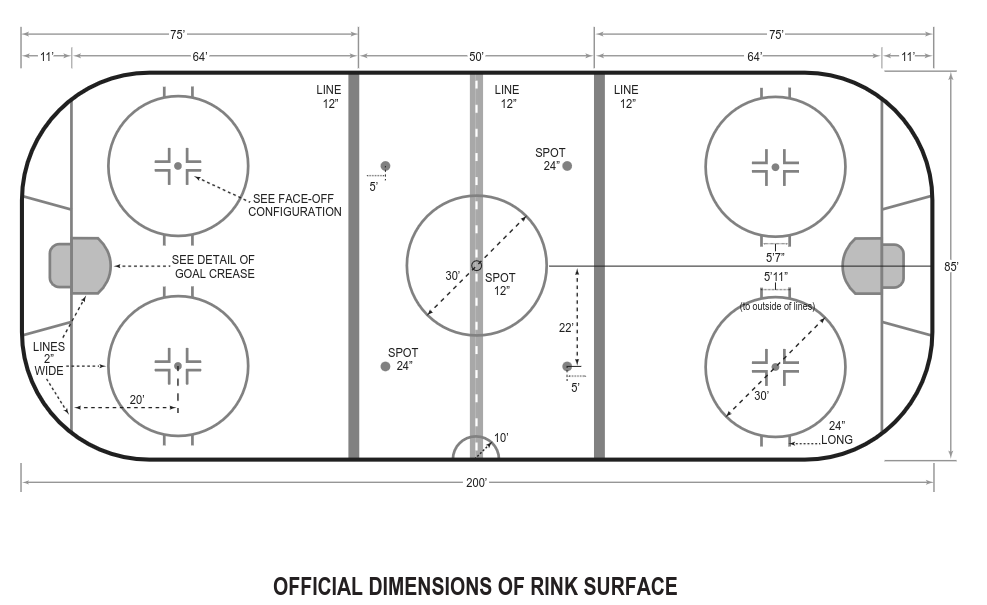

Hypotheses:

Si -25 < x < 25, zone N

Si 1ere ou 3eme periode (period%2 == 1): zone O <=> x < -25, zone D <=> x > 25

Si 2eme periode (period%2 == 0): zone O <=> x > 25, zone D <=> x < -25


PAS TOUT LE TEMPS VRAI!! SI LES BANCS DES JOUEURS DES EQUIPES ADVERSES NE SONT PAS DU MEME COTE, ALORS HOME TEAM CHOISI VERS QUEL COTE COMMENCER => VERIFIER QUELLES ARENAS ONT CETTE PROPRIETE

Lignes des buts: +- 89

In [ ]:
display(combined_shots.query('zone == "N"')['x'].describe())

,x
count,21363.0
mean,-0.264944
std,14.170241
min,-25.0
25%,-13.0
50%,0.0
75%,12.0
max,26.0


In [ ]:
combined_shots[['x', 'y']].describe()

,x,y
count,648256.000000,648257.000000
mean,-0.271023,-0.038642
std,64.015391,19.005531
min,-99.000000,-42.000000
25%,-64.000000,-14.000000
50%,-3.000000,0.000000
75%,64.000000,14.000000
max,99.000000,42.000000


Zone N : entre -25 et 26

In [ ]:
# Test des hypotheses
display(combined_shots.groupby(['game_id', 'period', 'team', 'zone'])['x'].describe())

KeyboardInterrupt: 

## 1.

Vous assurer que vous pouvez travailler correctement avec les coordonnées des événements. Cela inclut de vous assurer que les tirs sont du bon côté de la patinoire (en raison des changements de période, ou parce que les équipes commencent de côtés différents pendant un match), ainsi que de pouvoir convertir les coordonnées physiques en coordonnées de pixels sur la figure.

On va dire oui pour le moment

In [16]:
# On drop les valeurs NA (maintenant qu'on sait combien on en a pour chaque annees) (pris du TP)
# "Excluez les valeurs manquantes seulement des analyses qui en ont besoin, et rapportez le nombre d'événements exclus."
combined_shots_with_coordinates = combined_shots.dropna(subset=['x', 'y'])
print("Rows excluded from a coordinate-based analysis:", len(combined_shots) - len(combined_shots_with_coordinates))
print("Rows kept in the full shots table:", len(combined_shots))

Rows excluded from a coordinate-based analysis: 17
Rows kept in the full shots table: 648272


In [18]:
distances_features = ['event_id', 'period', 'period_type', 'team', 'is_home_team', 'zone', 'x', 'y', 'distance']

In [ ]:
# Inclure les SO?
combined_shots.groupby(['season', 'period'])['period_type'].value_counts()

season  period  period_type
2016    1       REG            25780
        2       REG            27377
        3       REG            25122
        4       OT              1480
        5       SO               601
                OT                39
2017    1       REG            28096
        2       REG            29479
        3       REG            27488
        4       OT              1406
        5       SO               635
                OT                33
2018    1       REG            27922
        2       REG            29063
        3       REG            27153
        4       OT              1249
        5       SO               524
                OT                28
2019    1       REG            23970
        2       REG            25388
        3       REG            23221
        4       OT              1254
        5       SO               523
                OT                56
        6       OT                22
        7       OT                22
        8       OT                 4
2020    1       REG            18496
        2       REG            19835
        3       REG            17970
        4       OT               996
        5       SO               375
                OT                56
        6       OT                 6
2021    1       REG            28737
        2       REG            30505
        3       REG            28366
        4       OT              1319
        5       SO               609
                OT                36
        6       OT                13
2022    1       REG            28132
        2       REG            30253
        3       REG            27643
        4       OT              1427
        5       SO               548
                OT                41
        6       OT                19
        7       OT                23
2023    1       REG            27129
        2       REG            29056
        3       REG            27061
        4       OT              1169
        5       SO               498
                OT                19
Name: count, dtype: int64

In [17]:
combined_shots_with_coordinates = compute_distance(combined_shots_with_coordinates)

In [ ]:
# Quelques verifs rapides: en zone O la distance est toujours inferieure a sqrt((89-25)**2 + (85/2)**2),
# en zone D toujours sup a sqrt((89+26)**2 + (85/2)**2), en zone N entre les deux
(np.sqrt((89-25)**2 + (85/2)**2), np.sqrt((89+26)**2 + (85/2)**2))

(np.float64(76.8261023350788), np.float64(122.60199835239229))

In [ ]:
combined_shots_with_coordinates[['zone', 'distance']].loc[combined_shots_with_coordinates['zone'] != 'SO'].groupby('zone').describe()

distance                                                             \
         count        mean        std         min         25%         50%   
zone                                                                        
D      11859.0  154.329300  19.506037  114.004386  137.931142  155.364089   
N      21384.0   80.993985   7.998510   63.000000   74.726167   81.252692   
O     615012.0   31.796712  17.332022    0.000000   15.811388   30.886890   

                              
             75%         max  
zone                          
D     170.836179  189.654950  
N      87.298339   98.412398  
O      46.010868   76.006579

In [ ]:
combined_shots_with_coordinates[['zone', 'distance']].loc[combined_shots_with_coordinates['zone'] != 'SO'].groupby('zone').describe()

distance                                                             \
         count        mean        std         min         25%         50%   
zone                                                                        
D      11859.0  154.329300  19.506037  114.004386  137.931142  155.364089   
N      21384.0   80.993985   7.998510   63.000000   74.726167   81.252692   
O     615012.0   31.796712  17.332022    0.000000   15.811388   30.886890   

                              
             75%         max  
zone                          
D     170.836179  189.654950  
N      87.298339   98.412398  
O      46.010868   76.006579

In [ ]:
combined_shots.columns

Index(['season', 'game_id', 'event_id', 'game_type', 'period', 'period_type',
       'time_in_period', 'team', 'team_id', 'is_home_team', 'event_type',
       'is_goal', 'x', 'y', 'player_name', 'goalie_name', 'shot_type', 'zone',
       'empty_net', 'away_goalie_in_net', 'away_skaters', 'home_skaters',
       'home_goalie_in_net', 'strength'],
      dtype='object')

In [ ]:
data_dir

PosixPath('/content/drive/MyDrive/ift6758/data')

In [ ]:
# Sauvegarde du tableau avec les donnees de distance
save_to_csv(combined_shots_with_coordinates, "combined_shots_distance", Path(data_dir / 'vizualisations/'))

Saved processed table: /content/drive/MyDrive/ift6758/data/vizualisations/combined_shots_distance.csv


## 2.
Calculer des statistiques agrégées des emplacements de tirs pour l'ensemble de la ligue afin d'obtenir le taux de tirs moyen par heure de la ligue. Pour chaque zone (bin) spatiale, divisez le nombre de tirs de toutes les équipes par 2 * nombre de matchs de la ligue pour cette saison : chaque match contribue deux heures-équipe selon l'hypothèse de 60 minutes. Vous pouvez faire quelques hypothèses simplificatrices :

    Vous pouvez supposer que tous les tirs sont à forces égales ; cela signifie que vous pouvez simplement agréger tous les tirs plutôt que de déterminer si un tir a été effectué à forces égales ou non (rappel : Q 4.2).
    Vous pouvez supposer que chaque match dure 60 minutes.


In [ ]:
def compute_excess_weighted_shots(shots_df, nxbin, nybin):
  """Prend un tidy tableau de tirs et calcule l'exces de tir par bin pour l'ensemble de la ligue et chaque annee

In [11]:
combined_shots_with_coordinates = pd.read_csv("/content/drive/MyDrive/ift6758/data/vizualisations/combined_shots_distance.csv")

In [16]:
# Pour bin les donnees, on ne prend pas les tirs en zone D. De plus, il faut considerer regrouper les coordonnees pour les periodes paires du meme cote que impair pour les afficher sur un seul cote de la patinoire.
# On va donc prendre les valeurs -x et -y pour les periodes%2 == 0

combined_shots_with_coordinates['xbin'] = combined_shots_with_coordinates['x'] * (combined_shots_with_coordinates['period']%2*2 - 1)
combined_shots_with_coordinates['ybin'] = combined_shots_with_coordinates['y'] * (combined_shots_with_coordinates['period']%2*2 - 1)


In [21]:
combined_shots_with_coordinates[distances_features + ['game_id', 'xbin', 'ybin']]

,event_id,period,period_type,team,is_home_team,zone,x,y,distance,game_id,xbin,ybin
0,8,1,REG,TOR,False,O,-77,5,13.000000,2016020001,-77,5
1,11,1,REG,OTT,True,O,86,13,13.341664,2016020001,86,13
2,15,1,REG,OTT,True,N,23,-38,76.157731,2016020001,23,-38
3,16,1,REG,OTT,True,O,33,-15,57.974132,2016020001,33,-15
4,24,1,REG,TOR,False,O,-34,28,61.717096,2016020001,-34,28
...,...,...,...,...,...,...,...,...,...,...,...,...
648250,252,3,REG,EDM,False,O,85,1,4.123106,2023030417,85,1
648251,1183,3,REG,FLA,True,O,-52,-27,45.803930,2023030417,-52,-27
648252,1189,3,REG,FLA,True,O,-59,-29,41.725292,2023030417,-59,-29
648253,1193,3,REG,EDM,False,O,57,-26,41.231056,2023030417,57,-26


In [22]:
# Adapte de https://stackoverflow.com/questions/43422961/2-dimensional-binning-with-pandas#43423056
xwidth = 20
ywidth = 10
combined_shots_with_coordinates["bins"] = list(zip(pd.cut(combined_shots_with_coordinates["xbin"], xwidth, labels=list(range(xwidth))),
                                                     pd.cut(combined_shots_with_coordinates["ybin"], ywidth, labels=list(range(ywidth)))))

In [51]:
# "Pour cette saison", "de toutes les equipes", "pour chaque bin"
shot_count_per_season_bin20x10 = combined_shots_with_coordinates.groupby(['season', 'bins']).size().rename('shots')
shot_count_per_season_bin20x10.sort_values(ascending=False)

season  bins   
2022    (18, 4)    3496
2023    (18, 4)    3374
2022    (1, 5)     3228
        (1, 4)     3208
2023    (1, 4)     3138
                   ... 
        (0, 9)        1
        (19, 0)       1
2019    (0, 9)        1
2017    (0, 0)        1
2016    (19, 0)       1
Name: shots, Length: 1590, dtype: int64

In [52]:
# On aplati le groupby dataframe, puis on separe les coordonnes des bins
shot_count_per_season_bin20x10 = shot_count_per_season_bin20x10.reset_index()
shot_count_per_season_bin20x10[['x', 'y']] = shot_count_per_season_bin20x10['bins'].to_list()
shot_count_per_season_bin20x10

,season,bins,shots,x,y
0,2016,"(0, 0)",4,0,0
1,2016,"(0, 1)",7,0,1
2,2016,"(0, 2)",14,0,2
3,2016,"(0, 3)",22,0,3
4,2016,"(0, 4)",25,0,4
...,...,...,...,...,...
1585,2023,"(19, 5)",120,19,5
1586,2023,"(19, 6)",96,19,6
1587,2023,"(19, 7)",68,19,7
1588,2023,"(19, 8)",27,19,8


In [53]:
shot_count_per_season_bin20x10

,season,bins,shots,x,y
0,2016,"(0, 0)",4,0,0
1,2016,"(0, 1)",7,0,1
2,2016,"(0, 2)",14,0,2
3,2016,"(0, 3)",22,0,3
4,2016,"(0, 4)",25,0,4
...,...,...,...,...,...
1585,2023,"(19, 5)",120,19,5
1586,2023,"(19, 6)",96,19,6
1587,2023,"(19, 7)",68,19,7
1588,2023,"(19, 8)",27,19,8


In [54]:
# Nombre de matchs par saison: on regroupe par saison et on compte le nombre de game_id unique
games_per_season = combined_shots_with_coordinates.groupby('season')['game_id'].nunique().rename('games')
games_per_season

,games
season,
2016,1317
2017,1355
2018,1358
2019,1168
2020,952
2021,1401
2022,1400
2023,1400


In [55]:
shot_count_per_season_bin20x10

,season,bins,shots,x,y
0,2016,"(0, 0)",4,0,0
1,2016,"(0, 1)",7,0,1
2,2016,"(0, 2)",14,0,2
3,2016,"(0, 3)",22,0,3
4,2016,"(0, 4)",25,0,4
...,...,...,...,...,...
1585,2023,"(19, 5)",120,19,5
1586,2023,"(19, 6)",96,19,6
1587,2023,"(19, 7)",68,19,7
1588,2023,"(19, 8)",27,19,8


In [56]:
shot_count_per_season_bin20x10['2-hrs-team'] = shot_count_per_season_bin20x10.apply(lambda row: row['shots']/(2*games_per_season[row['season']]), axis=1)

In [57]:
shot_count_per_season_bin20x10.sort_values(by='2-hrs-team',ascending=False)

,season,bins,shots,x,y,2-hrs-team
1375,2022,"(18, 4)",3496,18,4,1.248571
1574,2023,"(18, 4)",3374,18,4,1.205000
1206,2022,"(1, 5)",3228,1,5,1.152857
1205,2022,"(1, 4)",3208,1,4,1.145714
223,2017,"(2, 4)",3052,2,4,1.126199
...,...,...,...,...,...,...
189,2016,"(19, 0)",1,19,0,0.000380
199,2017,"(0, 0)",1,0,0,0.000369
1580,2023,"(19, 0)",1,19,0,0.000357
1200,2022,"(0, 9)",1,0,9,0.000357


Regrouper les tirs par équipe et utiliser le taux de tirs moyen par heure de la ligue calculé ci-dessus pour calculer le taux de tirs excédentaire par heure. Pour chaque zone, divisez le nombre de tirs de l'équipe par son nombre de matchs dans cette saison, puis soustrayez le taux de la ligue pour cette zone. Rapportez la différence brute en tirs par heure-équipe.

In [58]:
# "Par equipe"
shot_count_per_season_team_bin20x10 = combined_shots_with_coordinates.groupby(['season', 'team', 'bins']).size().rename('count')
shot_count_per_season_team_bin20x10.sort_values(ascending=False)

season  team  bins   
2023    EDM   (18, 4)    283
2022    EDM   (18, 4)    244
        NJD   (18, 4)    232
2017    TBL   (17, 4)    228
2022    CAR   (1, 4)     227
                        ... 
2023    WSH   (18, 9)      1
2021    NJD   (11, 2)      1
2016    ANA   (10, 2)      1
              (10, 5)      1
              (10, 6)      1
Name: count, Length: 43423, dtype: int64

In [ ]:
#shot_count_per_season_team_bin20x10.groupby(['season', 'team']).describe()

count       mean        std  min   25%   50%    75%    max
season team                                                            
2016   ANA   175.0  17.382857  21.647828  1.0  3.00  11.0  25.00  131.0
       ARI   175.0  13.177143  15.080533  1.0  3.00   9.0  18.00   94.0
       BOS   169.0  17.201183  18.327568  1.0  3.00  12.0  26.00  109.0
       BUF   176.0  14.295455  16.732626  1.0  3.00  11.0  20.00  102.0
       CAR   157.0  16.012739  17.126598  1.0  3.00  13.0  21.00   93.0
...            ...        ...        ...  ...   ...   ...    ...    ...
2023   TOR   182.0  15.967033  20.262613  1.0  4.00   9.5  19.75  132.0
       VAN   188.0  13.851064  18.705690  1.0  3.00   8.0  18.00  138.0
       VGK   186.0  14.784946  17.255379  1.0  4.00   9.0  20.00  122.0
       WPG   188.0  14.000000  16.677501  1.0  3.75  10.0  17.25  119.0
       WSH   182.0  12.637363  15.386739  1.0  3.00   9.0  16.00   94.0

[250 rows x 8 columns]

In [59]:
shot_count_per_season_team_bin20x10 = shot_count_per_season_team_bin20x10.reset_index()

In [35]:
save_to_csv(shot_count_per_season_team_bin20x10, "nbin20x10", Path(data_dir / 'vizualisations/'), overwrite=True)

Saved processed table: /content/drive/MyDrive/ift6758/data/vizualisations/nbin20x10.csv


In [60]:
games_per_season_team = combined_shots_with_coordinates.groupby(['season', 'team'])['game_id'].nunique().rename('games')
games_per_season_team

season  team
2016    ANA     99
        ARI     82
        BOS     88
        BUF     82
        CAR     82
                ..
2023    TOR     89
        VAN     95
        VGK     89
        WPG     87
        WSH     86
Name: games, Length: 250, dtype: int64

In [61]:
shot_count_per_season_bin20x10

,season,bins,shots,x,y,2-hrs-team
0,2016,"(0, 0)",4,0,0,0.001519
1,2016,"(0, 1)",7,0,1,0.002658
2,2016,"(0, 2)",14,0,2,0.005315
3,2016,"(0, 3)",22,0,3,0.008352
4,2016,"(0, 4)",25,0,4,0.009491
...,...,...,...,...,...,...
1585,2023,"(19, 5)",120,19,5,0.042857
1586,2023,"(19, 6)",96,19,6,0.034286
1587,2023,"(19, 7)",68,19,7,0.024286
1588,2023,"(19, 8)",27,19,8,0.009643


In [62]:
# On peut transformer l'ancienne table pour fetch les valeurs de 2-hrs-team dessus plus facilement
lookup_2ht = shot_count_per_season_bin20x10.set_index(['season', 'bins'])['2-hrs-team']

In [63]:
lookup_2ht

season  bins   
2016    (0, 0)     0.001519
        (0, 1)     0.002658
        (0, 2)     0.005315
        (0, 3)     0.008352
        (0, 4)     0.009491
                     ...   
2023    (19, 5)    0.042857
        (19, 6)    0.034286
        (19, 7)    0.024286
        (19, 8)    0.009643
        (19, 9)    0.001071
Name: 2-hrs-team, Length: 1590, dtype: float64

In [ ]:
# Il faudrait faire un pivot tout de suite?

In [65]:
shot_count_per_season_team_bin20x10['shot_per_team-hr'] = shot_count_per_season_team_bin20x10.apply(lambda row: row['count']/(games_per_season_team[(row['season'],row['team'])]) - lookup_2ht.loc[row['season'], row['bins']], axis=1)

In [71]:
shot_count_per_season_team_bin20x10.sort_values(by='shot_per_team-hr', ascending=False)

,season,team,bins,count,shot_per_team-hr
25222,2020,SJS,"(18, 4)",145,1.598214
39758,2023,EDM,"(18, 4)",283,1.439860
9600,2017,TOR,"(2, 4)",225,1.401891
34039,2022,EDM,"(18, 4)",244,1.347173
28437,2021,EDM,"(18, 5)",203,1.286632
...,...,...,...,...,...
23149,2020,EDM,"(1, 4)",4,-0.826190
26886,2021,BUF,"(1, 5)",12,-0.833316
24604,2020,OTT,"(2, 4)",7,-0.845063
36025,2022,SEA,"(1, 5)",28,-0.861190


In [73]:
# On separe les coordonnes des bins et on exporte pour la suite
shot_count_per_season_team_bin20x10[['x', 'y']] = shot_count_per_season_team_bin20x10['bins'].to_list()
save_to_csv(shot_count_per_season_team_bin20x10.drop(columns=['count', 'bins']), "excess_shots_bin20x10", Path(data_dir / 'vizualisations/'))

Saved processed table: /content/drive/MyDrive/ift6758/data/vizualisations/excess_shots_bin20x10.csv


In [70]:
shot_count_per_season_bin20x10

,season,bins,shots,x,y,2-hrs-team
0,2016,"(0, 0)",4,0,0,0.001519
1,2016,"(0, 1)",7,0,1,0.002658
2,2016,"(0, 2)",14,0,2,0.005315
3,2016,"(0, 3)",22,0,3,0.008352
4,2016,"(0, 4)",25,0,4,0.009491
...,...,...,...,...,...,...
1585,2023,"(19, 5)",120,19,5,0.042857
1586,2023,"(19, 6)",96,19,6,0.034286
1587,2023,"(19, 7)",68,19,7,0.024286
1588,2023,"(19, 8)",27,19,8,0.009643


In [ ]:
# Hacky et pas efficient a cause de .apply, p-e deja groupby -> pivot -> compute, utilisation de MultiIndex ?

shot_count_per_season_team_bin20x10['2-hrs-team'] = shot_count_per_season_team_bin20x10.apply(lambda row: row['count']/(2*games_per_season_team[(row['season'],row['team'])]), axis=1)

In [ ]:
shot_count_per_season_team_bin20x10.sort_values(by='2-hrs-team', ascending=False)

,season,team,bin20x10,count,2-hrs-team
40156,2023,EDM,"(18, 4)",210,0.981308
32968,2022,CAR,"(1, 4)",187,0.963918
25483,2020,SJS,"(18, 4)",101,0.901786
34379,2022,EDM,"(18, 4)",166,0.882979
35987,2022,OTT,"(18, 4)",143,0.871951
...,...,...,...,...,...
14939,2018,STL,"(8, 6)",1,0.004630
15039,2018,STL,"(19, 2)",1,0.004630
14941,2018,STL,"(8, 8)",1,0.004630
14942,2018,STL,"(8, 9)",1,0.004630


In [ ]:
# Essayons d'autres tailles de bin
combined_shots_with_coordinates["bin5x5"] = list(zip(pd.cut(combined_shots_with_coordinates["x"], 40, labels=list(range(40))),
                                                     pd.cut(combined_shots_with_coordinates["y"], 17, labels=list(range(17)))))

In [ ]:
shot_count_per_season_team_bin5x5 = combined_shots_with_coordinates.groupby(['season', 'team', 'bin5x5']).size().rename('count')
shot_count_per_season_team_bin5x5.sort_values(ascending=False)

season  team  bin5x5 
2023    EDM   (36, 8)    106
2022    CAR   (3, 8)      93
        VGK   (3, 8)      91
        EDM   (36, 8)     91
2021    TBL   (36, 8)     90
                        ... 
2023    WSH   (37, 3)      1
              (35, 0)      1
              (35, 1)      1
2016    ANA   (3, 15)      1
              (3, 2)       1
Name: count, Length: 115898, dtype: int64

In [ ]:
shot_count_per_season_team_bin5x5.groupby(['season', 'team']).describe()

count      mean       std  min  25%  50%  75%   max
season team                                                     
2016   ANA   471.0  6.458599  8.297775  1.0  2.0  5.0  8.0  74.0
       ARI   449.0  5.135857  5.987843  1.0  2.0  4.0  6.0  54.0
       BOS   455.0  6.389011  6.466475  1.0  2.0  5.0  9.0  67.0
       BUF   464.0  5.422414  6.661064  1.0  2.0  4.0  7.0  72.0
       CAR   440.0  5.713636  6.058169  1.0  2.0  4.0  7.0  42.0
...            ...       ...       ...  ...  ...  ...  ...   ...
2023   TOR   511.0  5.686888  7.144709  1.0  2.0  4.0  7.0  70.0
       VAN   490.0  5.314286  7.013513  1.0  2.0  3.0  7.0  88.0
       VGK   501.0  5.489022  6.204062  1.0  2.0  4.0  7.0  60.0
       WPG   513.0  5.130604  5.912819  1.0  2.0  4.0  6.0  53.0
       WSH   484.0  4.752066  5.706458  1.0  2.0  3.0  6.0  55.0

[250 rows x 8 columns]

In [ ]:
shot_count_per_season_team_bin5x5 = shot_count_per_season_team_bin5x5.reset_index()

In [ ]:
shot_count_per_season_team_bin5x5

,season,team,bin5x5,count
0,2016,ANA,"(0, 11)",1
1,2016,ANA,"(1, 3)",1
2,2016,ANA,"(1, 5)",1
3,2016,ANA,"(1, 6)",1
4,2016,ANA,"(1, 9)",2
...,...,...,...,...
115893,2023,WSH,"(38, 12)",2
115894,2023,WSH,"(39, 6)",1
115895,2023,WSH,"(39, 7)",1
115896,2023,WSH,"(39, 9)",1


In [ ]:
save_to_csv(shot_count_per_season_team_bin5x5, "nbin5x5_2", Path(data_dir / 'vizualisations/'), overwrite=True)

Saved processed table: /content/drive/MyDrive/ift6758/data/vizualisations/nbin5x5_2.csv


In [ ]:
shot_count_per_season_team_bin5x5['2-hrs-team'] = shot_count_per_season_team_bin5x5.apply(lambda row: row['count']/(2*games_per_season_team[(row['season'],row['team'])]), axis=1)

In [ ]:
shot_count_per_season_team_bin5x5.sort_values(by='2-hrs-team', ascending=False)

,season,team,bin5x5,count_per_bin,2-hrs-team
105889,2023,EDM,"(36, 8)",106,0.495327
90237,2022,EDM,"(36, 8)",91,0.484043
80389,2021,PIT,"(35, 8)",86,0.483146
94583,2022,OTT,"(36, 8)",79,0.481707
86427,2022,CAR,"(3, 8)",93,0.479381
...,...,...,...,...,...
39756,2018,STL,"(38, 7)",1,0.004630
39754,2018,STL,"(38, 4)",1,0.004630
39752,2018,STL,"(37, 13)",1,0.004630
39742,2018,STL,"(37, 2)",1,0.004630
